# Notebook 16: Transform sensitivity and the additivity claim

Addresses **Reviewer 2 #4**: *the Introduction motivates NMF because power is "additive and
strictly non-negative" and the constraint "matches the physics of the measurement", but the
features are then log-transformed and scaled to [0, 1]; clarify how these steps affect the
interpretation of the components, particularly the claim that the decomposition reflects
additivity on the original power scale.*

## The point being conceded, and what it costs

The reviewer is right: a sum of components in logarithmic units is a product of factors in
power units, so the published factorisation carries no claim about the additive composition
of scalp power. That sentence in the Introduction is an overstatement and will be withdrawn
whatever this notebook shows.

What survives the concession is narrower and worth establishing precisely: power is bounded
below by zero, and every step of the transform preserves that bound and is monotone within
each feature, so a component remains a non-negative pattern and a loading remains a
magnitude that cannot be negative. No part of the description depends on cancellation.

This notebook settles the empirical question that follows. If the sex association survives on
a scale where the factorisation *is* additive in power, the narrower claim can be made with
evidence. If it does not, the transform is load-bearing and the response must say that the
logarithmic step is applied for numerical reasons and that additivity in power is not
claimed at all.

## The variants

Each refits the whole pipeline at k = 5 on the same 86 x 350 raw feature matrix, changing
only the transform. Variants are ordered from the published pipeline towards untouched power.

| Variant | Transform | Additive in |
|---|---|---|
| `published` | log1p, winsorise 2.5/97.5, per-feature min-max to [0, 1] | log units |
| `log_nowinsor` | log1p, per-feature min-max | log units |
| `log_maxscale` | log1p, winsorise, divide by per-feature max | log units, true zero kept |
| `linear_minmax` | winsorise, per-feature min-max | shifted power |
| `linear_maxscale` | winsorise, divide by per-feature max | **power** |
| `linear_raw` | none (power as recorded) | **power** |

The two `maxscale` variants and `linear_raw` are the ones that bear on the reviewer's
question: dividing by a per-feature maximum is a positive rescaling that preserves the ratio
scale and the true zero, so a factorisation there is additive in power up to a per-feature
constant. Min-max scaling subtracts a per-feature minimum and destroys that, which is worth
stating in Methods independently of the reviewer's point.

## Why attenuation is expected on linear power

Spectral power is heavy-tailed, and a Frobenius-loss factorisation of untransformed power
will be dominated by the few highest-variance features. The notebook quantifies that
dominance so the response can give the reason the transform is applied rather than merely
asserting it.

## Inputs and outputs

Inputs: `feature_matrix.csv`, `feature_matrix_raw.csv`, `metadata.csv`, `nmf_H.csv`,
`nmf_W.csv`, `posthoc_per_component.csv`, `omnibus_results.csv`

CSVs: `nb16_variant_components.csv`, `nb16_variant_sex.csv`, `nb16_feature_dominance.csv`
Figure: `nb16_fig_transforms.png` — 300 dpi
Summary: `nb16_summary.txt`

## Setup

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import NMF
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# --- NMF settings: identical to Notebook 02 ---
MAX_ITER = 500
TOL = 1e-4
RANDOM_SEED_BASE = 42
N_INIT_FULL = 50
PUBLISHED_K = 5

LOWER_PCT, UPPER_PCT = 2.5, 97.5

N_PERMUTATIONS = 5000
FDR_ALPHA = 0.05
PERM_SEED = 42

SEX_COL = "Gender"

print("Six transform variants, each refitted at k = 5 with 50 initialisations and screened")
print(f"against 17 variables with {N_PERMUTATIONS} permutations.")
print()
print("Expected runtime: roughly 5-15 min per variant, so 40-90 min in total. The variants")
print("are independent; the loop can be interrupted and the saved CSVs will hold what ran.")

Six transform variants, each refitted at k = 5 with 50 initialisations and screened
against 17 variables with 5000 permutations.

Expected runtime: roughly 5-15 min per variant, so 40-90 min in total. The variants
are independent; the loop can be interrupted and the saved CSVs will hold what ran.


## Load inputs

In [2]:
feature_matrix = pd.read_csv(OUTPUT_DIR / "feature_matrix.csv", index_col="participant_id")
feature_matrix_raw = pd.read_csv(OUTPUT_DIR / "feature_matrix_raw.csv", index_col="participant_id")
feature_matrix_raw = feature_matrix_raw.loc[feature_matrix.index, feature_matrix.columns]
metadata = (pd.read_csv(OUTPUT_DIR / "metadata.csv")
            .set_index("participant_id")
            .reindex(feature_matrix.index))
H_ref = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
W_ref = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")

COMP_LABELS = list(H_ref.index)
H_REF_ARR = H_ref.values
PIDS = feature_matrix.index.to_numpy()
N = len(PIDS)

raw_sex = metadata[SEX_COL].astype(str).str.strip().str.upper().str[0]
if not set(raw_sex.dropna().unique()) <= {"M", "F"}:
    raise ValueError(f"Could not read {SEX_COL!r} as M/F: "
                     f"{sorted(metadata[SEX_COL].dropna().unique())}")
SEX = raw_sex.values

PUBLISHED_EFFECTS = pd.read_csv(OUTPUT_DIR / "posthoc_per_component.csv")
PUBLISHED_EFFECTS = (PUBLISHED_EFFECTS[PUBLISHED_EFFECTS["variable"] == SEX_COL]
                     .set_index("component"))
PUB_OMNIBUS = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")
PUB_SEX = PUB_OMNIBUS[PUB_OMNIBUS["variable"] == SEX_COL].iloc[0]

print(f"{N} participants, {feature_matrix_raw.shape[1]} features")
print(f"Raw power range: [{feature_matrix_raw.values.min():.4g}, "
      f"{feature_matrix_raw.values.max():.4g}]")
print(f"Published omnibus statistic for sex: {PUB_SEX['observed_stat']:.4f}")

86 participants, 350 features
Raw power range: [0.02293, 542.1]
Published omnibus statistic for sex: 0.2742


## The transforms

Each returns a non-negative matrix, which NMF requires. `linear_raw` is the identity, kept in
the set so that the published pipeline can be read against doing nothing at all.

In [3]:
def winsorise(arr, lower_pct=LOWER_PCT, upper_pct=UPPER_PCT):
    """Cap each feature at its own percentiles, without reordering values."""
    lo = np.percentile(arr, lower_pct, axis=0)
    hi = np.percentile(arr, upper_pct, axis=0)
    return np.clip(arr, lo, hi)


def minmax(arr):
    """Affine map of each feature onto [0, 1]. Destroys the ratio scale."""
    fmin, fmax = arr.min(axis=0), arr.max(axis=0)
    span = fmax - fmin
    span[span == 0] = 1.0
    return (arr - fmin) / span


def maxscale(arr):
    """Divide each feature by its maximum. A positive rescaling: ratio scale and zero kept."""
    fmax = arr.max(axis=0)
    fmax[fmax == 0] = 1.0
    return arr / fmax


def t_published(raw):
    """log1p, winsorise, min-max. The published pipeline."""
    return minmax(winsorise(np.log1p(raw)))


def t_log_nowinsor(raw):
    """log1p, min-max. Isolates what the winsorisation contributes."""
    return minmax(np.log1p(raw))


def t_log_maxscale(raw):
    """log1p, winsorise, divide by maximum. Keeps the zero of the log scale."""
    return maxscale(winsorise(np.log1p(raw)))


def t_linear_minmax(raw):
    """Winsorise, min-max. No logarithm."""
    return minmax(winsorise(raw))


def t_linear_maxscale(raw):
    """Winsorise, divide by maximum. Additive in power up to a per-feature constant."""
    return maxscale(winsorise(raw))


def t_linear_raw(raw):
    """Power as recorded."""
    return np.asarray(raw, dtype=float)


VARIANTS = {
    "published":        t_published,
    "log_nowinsor":     t_log_nowinsor,
    "log_maxscale":     t_log_maxscale,
    "linear_minmax":    t_linear_minmax,
    "linear_maxscale":  t_linear_maxscale,
    "linear_raw":       t_linear_raw,
}
ADDITIVE_IN_POWER = {"published": False, "log_nowinsor": False, "log_maxscale": False,
                     "linear_minmax": False, "linear_maxscale": True, "linear_raw": True}

RAW = feature_matrix_raw.values
check = t_published(RAW)
dev = np.abs(check - feature_matrix.values).max()
print(f"'published' variant against feature_matrix.csv: max deviation {dev:.3e}")
if dev > 1e-6:
    print("WARNING: the published transform is not reproduced; the comparisons below are not")
    print("anchored to the published solution. Check LOWER_PCT/UPPER_PCT against Notebook 01.")
else:
    print("Published transform reproduced; the variants are anchored to the published solution.")

'published' variant against feature_matrix.csv: max deviation 5.551e-16
Published transform reproduced; the variants are anchored to the published solution.


## Shared helper functions

Reproduced from notebooks 02, 04 and 05.

In [4]:
def cosine_similarity_matrix(A, B):
    """Pairwise cosine similarity between rows of A and rows of B."""
    A_norm = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B_norm = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return A_norm @ B_norm.T


def match_to_reference(H_new, H_ref_arr=None):
    """Hungarian-match rows of H_new to the reference components."""
    if H_ref_arr is None:
        H_ref_arr = H_REF_ARR
    sim = cosine_similarity_matrix(H_ref_arr, H_new)
    row, col = linear_sum_assignment(-sim)
    cos = np.full(H_ref_arr.shape[0], np.nan)
    idx = np.full(H_ref_arr.shape[0], -1, dtype=int)
    cos[row] = sim[row, col]
    idx[row] = col
    return cos, idx


def fit_nmf_best(X, k, n_init, seed_base):
    """Fit NMF n_init times and return the lowest-error solution, as in Notebook 02."""
    best = None
    for i in range(n_init):
        model = NMF(n_components=k, init="random", random_state=seed_base + i,
                    max_iter=MAX_ITER, tol=TOL, beta_loss="frobenius", solver="cd")
        W = model.fit_transform(X)
        if best is None or model.reconstruction_err_ < best[2]:
            best = (W, model.components_, model.reconstruction_err_)
    return best


def rb_female_higher(values, sex_arr):
    """Mann-Whitney rank-biserial and p; positive means higher in female participants."""
    values = np.asarray(values, dtype=float)
    f = values[np.asarray(sex_arr) == "F"]
    m = values[np.asarray(sex_arr) == "M"]
    if len(f) < 3 or len(m) < 3:
        return np.nan, np.nan
    if np.allclose(values, values[0]):
        return 0.0, 1.0
    u, p = stats.mannwhitneyu(m, f, alternative="two-sided")
    return float(1 - (2 * u) / (len(m) * len(f))), float(p)


def make_logreg():
    """LogisticRegression, tolerating the removal of multi_class in newer scikit-learn."""
    try:
        return LogisticRegression(max_iter=2000, multi_class="auto", solver="lbfgs")
    except TypeError:
        return LogisticRegression(max_iter=2000, solver="lbfgs")


def log_likelihood_logistic(model, X, y):
    """Log-likelihood of a fitted logistic model."""
    proba = np.clip(model.predict_proba(X), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    ll = 0.0
    for cls_idx, cls in enumerate(model.classes_):
        ll += np.sum(np.log(proba[y == cls, cls_idx]))
    return ll


def compute_statistic_classification(X, y):
    """McFadden pseudo-R-squared."""
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = make_logreg().fit(X, y)
        ll_full = log_likelihood_logistic(full, X, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    if ll_null == 0:
        return np.nan
    return 1 - (ll_full / ll_null)


def compute_statistic(X, y, vtype):
    """Dispatch to the statistic matching the variable's measurement scale."""
    if vtype == "continuous":
        return LinearRegression().fit(X, y).score(X, y)
    if vtype in ("binary", "multi"):
        return compute_statistic_classification(X, y)
    raise ValueError(f"Unknown vtype: {vtype}")


VAR_TYPES = {
    "Age":                               "continuous",
    "Gender":                            "binary",
    "Residential Area (Urban/Rural)":    "binary",
    "From City":                         "binary",
    "Single/NotSingle":                  "binary",
    "Education":                         "multi",
    "Field of Study":                    "multi",
    "Occupation":                        "multi",
    "# of LanguagesSpeak":               "continuous",
    "UsedToDoSport":                     "binary",
    "NowDoingSports_aWeek":              "continuous",
    "PlayingAnInstrument":               "binary",
    "History of Neurological Disorders": "binary",
    "Medication Usage":                  "binary",
    "Average Sleep Hours per Night":     "continuous",
    "Smoking (0,1,2,3)":                 "continuous",
    "Alchocol (0,1,2,3)":                "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}


def omnibus_screen(W_mat, n_perm, seed, verbose_var=None):
    """Notebook 04's omnibus permutation screen, applied to an arbitrary embedding."""
    rng = np.random.default_rng(seed)
    W_std = StandardScaler().fit_transform(W_mat)
    rows = []
    for var, vtype in VAR_TYPES.items():
        sub = pd.DataFrame({"y": metadata[var].values})
        sub["idx"] = np.arange(len(sub))
        sub = sub.dropna()
        if len(sub) < 10:
            rows.append({"variable": var, "type": vtype, "n": len(sub),
                         "observed_stat": np.nan, "p_perm": np.nan})
            continue
        X_use = W_std[sub["idx"].values]
        y_raw = sub["y"].values
        if vtype != "continuous":
            y_use, _ = pd.factorize(y_raw)
        else:
            y_num = pd.to_numeric(y_raw, errors="coerce")
            valid = ~pd.isna(y_num)
            if valid.sum() < 10:
                rows.append({"variable": var, "type": vtype, "n": int(valid.sum()),
                             "observed_stat": np.nan, "p_perm": np.nan})
                continue
            X_use = X_use[valid]
            y_use = np.asarray(y_num[valid], dtype=float)
        obs = compute_statistic(X_use, y_use, vtype)
        if np.isnan(obs):
            rows.append({"variable": var, "type": vtype, "n": len(y_use),
                         "observed_stat": np.nan, "p_perm": np.nan})
            continue
        null = np.zeros(n_perm)
        y_perm = np.array(y_use, copy=True)
        for i in range(n_perm):
            rng.shuffle(y_perm)
            null[i] = compute_statistic(X_use, y_perm, vtype)
        rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                     "null_mean": float(np.mean(null)),
                     "p_perm": (np.sum(null >= obs) + 1) / (n_perm + 1)})
        if verbose_var and var == verbose_var:
            print(f"    {var}: stat={obs:.4f}, p_perm={rows[-1]['p_perm']:.4f}")
    out = pd.DataFrame(rows)
    ok = out["p_perm"].notna()
    out["p_fdr"] = np.nan
    out["significant_fdr"] = False
    if ok.any():
        reject, p_fdr, _, _ = multipletests(out.loc[ok, "p_perm"].values,
                                            alpha=FDR_ALPHA, method="fdr_bh")
        out.loc[ok, "p_fdr"] = p_fdr
        out.loc[ok, "significant_fdr"] = reject
    return out.sort_values("p_perm")


print(f"{len(VAR_TYPES)} metadata variables available")

17 metadata variables available


## Part A — Feature dominance under each transform

Why the logarithmic step is applied, quantified. For each variant: the share of total
variance carried by the single highest-variance feature and by the top ten, and the ratio of
the largest to the median feature variance. A variant in which a handful of features carry
most of the variance will produce a factorisation describing those features rather than the
montage.

In [5]:
dom_rows = []
for name, fn in VARIANTS.items():
    X = fn(RAW)
    v = X.var(axis=0)
    total = v.sum()
    order = np.argsort(v)[::-1]
    dom_rows.append({
        "variant": name,
        "additive_in_power": ADDITIVE_IN_POWER[name],
        "top1_share": float(v[order[0]] / total) if total > 0 else np.nan,
        "top10_share": float(v[order[:10]].sum() / total) if total > 0 else np.nan,
        "max_over_median_var": float(v.max() / np.median(v)) if np.median(v) > 0 else np.inf,
        "value_range": float(X.max() - X.min()),
    })
dom_df = pd.DataFrame(dom_rows)
dom_df.to_csv(OUTPUT_DIR / "nb16_feature_dominance.csv", index=False)
print("Feature dominance by variant (share of total variance):")
print(dom_df.round(4).to_string(index=False))
print()
print("A high top1 or top10 share means the factorisation is describing a few features")
print("rather than the montage, which is the numerical reason the transform is applied.")

Feature dominance by variant (share of total variance):
        variant  additive_in_power  top1_share  top10_share  max_over_median_var  value_range
      published              False      0.0041       0.0379               1.4281       1.0000
   log_nowinsor              False      0.0047       0.0456               1.6564       1.0000
   log_maxscale              False      0.0048       0.0441               1.7087       0.9682
  linear_minmax              False      0.0045       0.0394               1.5879       1.0000
linear_maxscale               True      0.0044       0.0406               1.5692       0.9866
     linear_raw               True      0.3943       0.8975            5615.8942     542.1270

A high top1 or top10 share means the factorisation is describing a few features
rather than the montage, which is the numerical reason the transform is applied.


## Part B — Refit and test each variant

In [6]:
comp_rows, sex_rows = [], []
for name, fn in VARIANTS.items():
    t0 = time.time()
    X = fn(RAW)
    if not np.isfinite(X).all():
        print(f"=== {name}: non-finite values after transform; skipped ===")
        continue
    if (X < 0).any():
        print(f"=== {name}: negative values after transform; skipped (NMF requires "
              f"non-negativity) ===")
        continue
    W_v, H_v, err_v = fit_nmf_best(X, PUBLISHED_K, N_INIT_FULL, RANDOM_SEED_BASE)
    cos, idx = match_to_reference(H_v)
    print(f"=== {name} ===")
    print(f"  additive in power: {ADDITIVE_IN_POWER[name]} | reconstruction error {err_v:.4f}")
    print(f"  cosine to published components: {np.round(cos, 3)}")

    omni = omnibus_screen(W_v, N_PERMUTATIONS, PERM_SEED, verbose_var=SEX_COL)
    srow = omni[omni["variable"] == SEX_COL].iloc[0]
    survivors = list(omni[omni["significant_fdr"]]["variable"])
    print(f"  omnibus sex: stat={srow['observed_stat']:.4f}, p_perm={srow['p_perm']:.4f}, "
          f"p_fdr={srow['p_fdr']:.4f} (published {PUB_SEX['observed_stat']:.4f})")
    print(f"  variables surviving FDR: {survivors if survivors else 'none'}")

    per = []
    for ci, lab in enumerate(COMP_LABELS):
        r, p = rb_female_higher(W_v[:, idx[ci]], SEX)
        per.append({"component": lab, "rank_biserial": r, "p_raw": p})
    per = pd.DataFrame(per)
    ok = per["p_raw"].notna()
    per["p_fdr"] = np.nan
    if ok.any():
        _, pf, _, _ = multipletests(per.loc[ok, "p_raw"].values, alpha=FDR_ALPHA,
                                    method="fdr_bh")
        per.loc[ok, "p_fdr"] = pf
    print("  per-component sex effects:")
    print(per.round(4).to_string(index=False))
    sig = per[per["p_fdr"] < FDR_ALPHA]
    pos = int((sig["rank_biserial"] > 0).sum())
    neg = int((sig["rank_biserial"] < 0).sum())
    verdict = ("opposing pair present" if pos >= 1 and neg >= 1
               else "no opposing pair" if len(sig) else "no component survives correction")
    print(f"  -> {verdict}")
    print(f"  ({time.time() - t0:.0f}s)")
    print()

    for ci, lab in enumerate(COMP_LABELS):
        comp_rows.append({"variant": name, "additive_in_power": ADDITIVE_IN_POWER[name],
                          "component": lab, "cosine_to_published": cos[ci],
                          "rank_biserial": per.loc[ci, "rank_biserial"],
                          "p_raw": per.loc[ci, "p_raw"], "p_fdr": per.loc[ci, "p_fdr"],
                          "published_r": PUBLISHED_EFFECTS["effect_size"].get(lab, np.nan)})
    sex_rows.append({"variant": name, "additive_in_power": ADDITIVE_IN_POWER[name],
                     "omnibus_stat": srow["observed_stat"], "p_perm": srow["p_perm"],
                     "p_fdr": srow["p_fdr"], "significant_fdr": bool(srow["significant_fdr"]),
                     "n_survivors": len(survivors), "recon_error": err_v,
                     "opposing_pair": verdict})
    pd.DataFrame(comp_rows).to_csv(OUTPUT_DIR / "nb16_variant_components.csv", index=False)
    pd.DataFrame(sex_rows).to_csv(OUTPUT_DIR / "nb16_variant_sex.csv", index=False)

comp_df = pd.DataFrame(comp_rows)
sex_df = pd.DataFrame(sex_rows)
print(sex_df.round(4).to_string(index=False))

=== published ===
  additive in power: False | reconstruction error 22.7852
  cosine to published components: [1. 1. 1. 1. 1.]
    Gender: stat=0.2742, p_perm=0.0002
  omnibus sex: stat=0.2742, p_perm=0.0002, p_fdr=0.0034 (published 0.2742)
  variables surviving FDR: ['Gender']
  per-component sex effects:
component  rank_biserial  p_raw  p_fdr
   comp_1         0.5768 0.0000 0.0000
   comp_2         0.1331 0.2898 0.4830
   comp_3         0.0400 0.7523 0.7523
   comp_4        -0.3144 0.0122 0.0304
   comp_5        -0.0574 0.6498 0.7523
  -> opposing pair present
  (286s)

=== log_nowinsor ===
  additive in power: False | reconstruction error 17.2097
  cosine to published components: [0.974 0.954 0.945 0.985 0.976]
    Gender: stat=0.2233, p_perm=0.0004
  omnibus sex: stat=0.2233, p_perm=0.0004, p_fdr=0.0068 (published 0.2742)
  variables surviving FDR: ['Gender']
  per-component sex effects:
component  rank_biserial  p_raw  p_fdr
   comp_1         0.5184 0.0000 0.0002
   comp_2        

### Figure

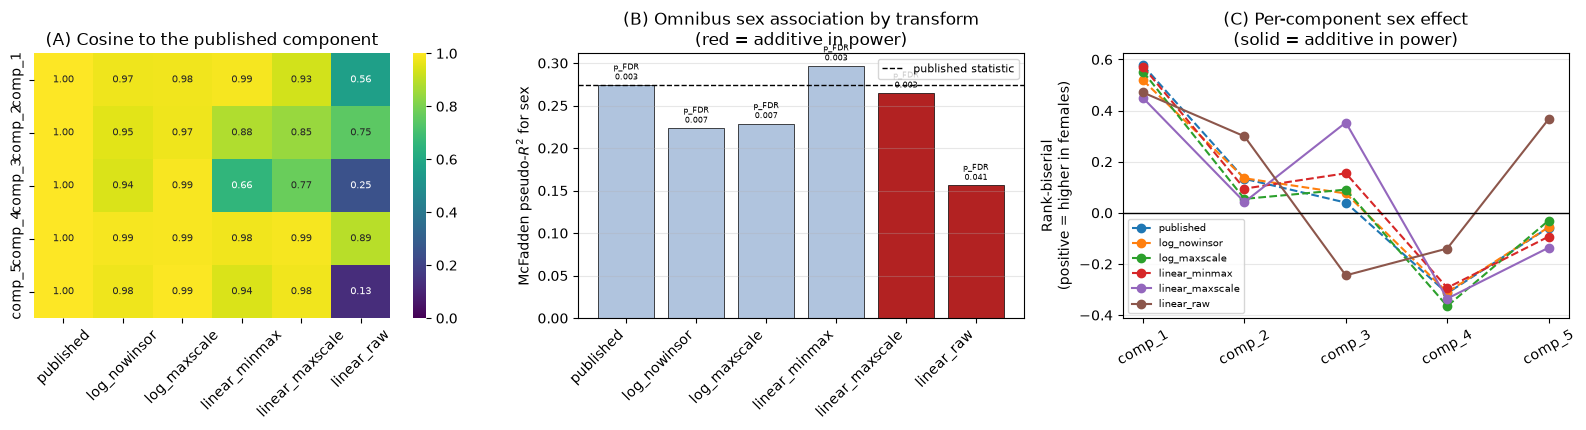

In [7]:
if len(comp_df):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    variants_run = list(sex_df["variant"])

    ax = axes[0]
    piv = comp_df.pivot(index="component", columns="variant",
                        values="cosine_to_published").reindex(COMP_LABELS)[variants_run]
    sns.heatmap(piv, ax=ax, cmap="viridis", vmin=0, vmax=1, annot=True, fmt=".2f",
                annot_kws={"size": 7})
    ax.set_title("(A) Cosine to the published component")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)

    ax = axes[1]
    colours = ["firebrick" if a else "lightsteelblue" for a in sex_df["additive_in_power"]]
    ax.bar(range(len(sex_df)), sex_df["omnibus_stat"], color=colours, edgecolor="black",
           linewidth=0.5)
    ax.axhline(PUB_SEX["observed_stat"], color="black", linestyle="--", linewidth=1,
               label="published statistic")
    for i, r in sex_df.reset_index(drop=True).iterrows():
        ax.annotate(f"p_FDR\n{r['p_fdr']:.3f}", (i, r["omnibus_stat"]),
                    textcoords="offset points", xytext=(0, 4), ha="center", fontsize=6)
    ax.set_xticks(range(len(sex_df)))
    ax.set_xticklabels(sex_df["variant"], rotation=45, ha="right")
    ax.set_ylabel("McFadden pseudo-$R^2$ for sex")
    ax.set_title("(B) Omnibus sex association by transform\n(red = additive in power)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")

    ax = axes[2]
    x = np.arange(len(COMP_LABELS))
    for name in variants_run:
        sub = comp_df[comp_df["variant"] == name].set_index("component").reindex(COMP_LABELS)
        style = "-" if ADDITIVE_IN_POWER[name] else "--"
        ax.plot(x, sub["rank_biserial"], marker="o", linestyle=style, label=name)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(COMP_LABELS, rotation=30)
    ax.set_ylabel("Rank-biserial\n(positive = higher in females)")
    ax.set_title("(C) Per-component sex effect\n(solid = additive in power)")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3, axis="y")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "nb16_fig_transforms.png", dpi=300, bbox_inches="tight")
    plt.show()

## Summary for the response letter

In [8]:
lines = []


def w(s=""):
    """Print and record a summary line."""
    print(s)
    lines.append(s)


w("=" * 72)
w("NOTEBOOK 16 SUMMARY - transform sensitivity (R2.4)")
w("=" * 72)
w(f"Published omnibus statistic for sex: {PUB_SEX['observed_stat']:.4f} "
  f"(p_FDR {PUB_SEX['p_fdr']:.4f})")
w("")
w("FEATURE DOMINANCE BY TRANSFORM")
for _, r in dom_df.iterrows():
    w(f"  {r['variant']:17s} additive in power: {str(r['additive_in_power']):5s} | "
      f"top feature {100 * r['top1_share']:.1f}% of variance, top ten "
      f"{100 * r['top10_share']:.1f}%, max/median variance {r['max_over_median_var']:.1f}")
w("")
w("OMNIBUS SEX ASSOCIATION BY TRANSFORM")
for _, r in sex_df.iterrows():
    w(f"  {r['variant']:17s} stat {r['omnibus_stat']:.4f}, p_perm {r['p_perm']:.4f}, "
      f"p_FDR {r['p_fdr']:.4f}{' *' if r['significant_fdr'] else ''} | {r['opposing_pair']}")
w("")
w("PER-COMPONENT SEX EFFECTS BY TRANSFORM")
for name in sex_df["variant"]:
    sub = comp_df[comp_df["variant"] == name].set_index("component").reindex(COMP_LABELS)
    w(f"  {name} (additive in power: {ADDITIVE_IN_POWER[name]}):")
    for lab in COMP_LABELS:
        w(f"    {lab}: r {sub.loc[lab, 'rank_biserial']:+.3f} "
          f"(p_FDR {sub.loc[lab, 'p_fdr']:.4f}), cosine to published "
          f"{sub.loc[lab, 'cosine_to_published']:.3f}")
w("")
additive_run = sex_df[sex_df["additive_in_power"]]
if len(additive_run):
    held = additive_run[additive_run["significant_fdr"]]
    w("VERDICT ON THE ADDITIVITY CLAIM")
    if len(held):
        w(f"  The association survives correction on {len(held)} of {len(additive_run)} "
          "transforms that keep the ratio scale of power:")
        for _, r in held.iterrows():
            w(f"    {r['variant']}: stat {r['omnibus_stat']:.4f}, p_FDR {r['p_fdr']:.4f}, "
              f"{r['opposing_pair']}")
        w("  The narrower claim can therefore be made with evidence: the structure is not an")
        w("  artefact of the logarithmic transform, even though the published factorisation is")
        w("  additive in log units rather than in power.")
    else:
        w("  The association does not survive correction on any transform that keeps the ratio")
        w("  scale of power. The logarithmic step is therefore load-bearing, and the response")
        w("  should state that it is applied for numerical reasons and that additivity in power")
        w("  is not claimed at all, rather than presenting this as a robustness result.")
w("")
w("=" * 72)

with open(OUTPUT_DIR / "nb16_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print()
print(f"Saved {OUTPUT_DIR / 'nb16_summary.txt'}")

NOTEBOOK 16 SUMMARY - transform sensitivity (R2.4)
Published omnibus statistic for sex: 0.2742 (p_FDR 0.0034)

FEATURE DOMINANCE BY TRANSFORM
  published         additive in power: False | top feature 0.4% of variance, top ten 3.8%, max/median variance 1.4
  log_nowinsor      additive in power: False | top feature 0.5% of variance, top ten 4.6%, max/median variance 1.7
  log_maxscale      additive in power: False | top feature 0.5% of variance, top ten 4.4%, max/median variance 1.7
  linear_minmax     additive in power: False | top feature 0.4% of variance, top ten 3.9%, max/median variance 1.6
  linear_maxscale   additive in power: True  | top feature 0.4% of variance, top ten 4.1%, max/median variance 1.6
  linear_raw        additive in power: True  | top feature 39.4% of variance, top ten 89.8%, max/median variance 5615.9

OMNIBUS SEX ASSOCIATION BY TRANSFORM
  published         stat 0.2742, p_perm 0.0002, p_FDR 0.0034 * | opposing pair present
  log_nowinsor      stat 0.2233, p_per